# Titanic | Nettoyage, visualisation et export

Ce notebook prepare les fichiers d'entraînement et de test à partir des CSV de la couche Bronze. Il traite les valeurs manquantes, présente quelques visualisations descriptives et enregistre les jeux nettoyés ainsi qu'un rapport de contrôle.

> **Périmètre :** les sources de `data/bronze/` restent inchangées. Les résultats sont créés dans `data/processed/` et `reports/figures/`. La modélisation et la soumission Kaggle restent dans le notebook 03.

In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## 1. Imports et localisation du projet

Le dossier du projet est détecté automatiquement depuis le répertoire courant ou l'un de ses parents. Les dépendances sont limitées à pandas et matplotlib.

In [14]:
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (current_dir, *current_dir.parents)
        if (candidate / "data" / "bronze").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Impossible de localiser data/bronze depuis {current_dir}. "
        "Lancez le notebook depuis le projet ou l'un de ses sous-dossiers."
    )

BRONZE_DIR = PROJECT_ROOT / "data" / "bronze"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TRAIN_PATH = BRONZE_DIR / "train.csv"
TEST_PATH = BRONZE_DIR / "test.csv"

for file_path in (TRAIN_PATH, TEST_PATH):
    if not file_path.is_file():
        raise FileNotFoundError(f"Fichier source introuvable : {file_path}")

print(f"Racine du projet : {PROJECT_ROOT}")
print(f"Sources : {BRONZE_DIR}")
print(f"Dossier des jeux nettoyés : {PROCESSED_DIR}")
print(f"Dossier des visualisations : {FIGURES_DIR}")

Racine du projet : C:\Users\hp\Downloads\titanic
Sources : C:\Users\hp\Downloads\titanic\data\bronze
Dossier des jeux nettoyés : C:\Users\hp\Downloads\titanic\data\processed
Dossier des visualisations : C:\Users\hp\Downloads\titanic\reports\figures


## 2. Chargement et validation des sources

Les colonnes indispensables et les identifiants sont vérifiés avant le nettoyage. 

Le jeu de test ne doit pas contenir la cible `Survived`.

In [15]:
try:
    df_train = pd.read_csv(TRAIN_PATH, low_memory=False)
    df_test = pd.read_csv(TEST_PATH, low_memory=False)
except (pd.errors.EmptyDataError, pd.errors.ParserError, UnicodeDecodeError) as exc:
    raise ValueError(f"Impossible de lire un fichier source : {exc}") from exc

if df_train.empty or df_test.empty:
    raise ValueError("Les fichiers d'entraînement et de test doivent contenir des lignes.")

required_train = {
    "PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked",
}
required_test = required_train - {"Survived"}
for frame, required, name in (
    (df_train, required_train, "train.csv"),
    (df_test, required_test, "test.csv"),
):
    missing_columns = sorted(required.difference(frame.columns))
    if missing_columns:
        raise ValueError(f"{name} : colonnes requises absentes : {missing_columns}")
    if frame["PassengerId"].isna().any() or frame["PassengerId"].duplicated().any():
        raise ValueError(f"{name} : PassengerId doit être présent et unique.")

if "Survived" in df_test.columns:
    raise ValueError("test.csv ne doit pas contenir la cible Survived.")
if not df_train["Survived"].isin([0, 1]).all():
    raise ValueError("La cible Survived doit contenir uniquement 0 ou 1.")

print(f"Train : {len(df_train):,} lignes × {len(df_train.columns)} colonnes")
print(f"Test : {len(df_test):,} lignes × {len(df_test.columns)} colonnes")

Train : 891 lignes × 12 colonnes
Test : 418 lignes × 11 colonnes


## 3. Copies de travail et valeurs manquantes

Toutes les transformations sont effectuées sur des copies. Les valeurs manquantes et les anomalies simples (`Age` hors de 0 à 100 ans, `Fare` négatif) sont recensées avant traitement.

In [4]:
train_clean = df_train.copy()
test_clean = df_test.copy()

for frame in (train_clean, test_clean):
    frame["Age"] = pd.to_numeric(frame["Age"], errors="coerce")
    frame["Fare"] = pd.to_numeric(frame["Fare"], errors="coerce")
    frame.loc[~frame["Age"].between(0, 100), "Age"] = pd.NA
    frame.loc[frame["Fare"] < 0, "Fare"] = pd.NA

missing_before = pd.DataFrame(
    {
        "Entraînement": train_clean.isna().sum(),
        "Test": test_clean.reindex(columns=train_clean.columns).isna().sum(),
    }
).fillna(0).astype(int)
display(missing_before.rename_axis("Variable"))

,Entraînement,Test
Variable,,
PassengerId,0,0
Survived,0,418
Pclass,0,0
Name,0,0
Sex,0,0
Age,177,86
SibSp,0,0
Parch,0,0
Ticket,0,0


## 4. Traitement et construction des jeux nettoyés

Les médianes de `Age` et `Fare`, ainsi que la modalité la plus fréquente de `Embarked`, sont apprises sur l'entraînement puis appliquées aux deux jeux. Pour `Cabin`, la lettre du pont est extraite dans `Deck` et les valeurs inconnues reçoivent la catégorie `Unknown` ; la colonne `Cabin` d'origine est ensuite retirée.

In [5]:
age_median = train_clean["Age"].median()
fare_median = train_clean["Fare"].median()
embarked_mode = train_clean["Embarked"].mode(dropna=True)

if pd.isna(age_median):
    raise ValueError("Impossible de calculer la médiane de Age dans train.csv.")
if pd.isna(fare_median):
    raise ValueError("Impossible de calculer la médiane de Fare dans train.csv.")
if embarked_mode.empty:
    raise ValueError("Impossible de déterminer la modalité la plus fréquente de Embarked.")

for frame in (train_clean, test_clean):
    frame["Age"] = frame["Age"].fillna(age_median)
    frame["Fare"] = frame["Fare"].fillna(fare_median)
    frame["Embarked"] = frame["Embarked"].fillna(embarked_mode.iloc[0])
    frame["Deck"] = (
        frame["Cabin"].astype("string").str.extract(r"^\s*([A-Za-z])", expand=False)
        .str.upper().fillna("Unknown")
    )
    frame.drop(columns="Cabin", inplace=True)

feature_columns = [column for column in train_clean.columns if column != "Survived"]
test_clean = test_clean[feature_columns]
train_clean = train_clean[["PassengerId", "Survived", *feature_columns[1:]]]

imputation_values = pd.DataFrame(
    {
        "Méthode": ["Médiane (entraînement)", "Médiane (entraînement)", "Mode (entraînement)"],
        "Valeur": [age_median, fare_median, embarked_mode.iloc[0]],
    },
    index=pd.Index(["Age", "Fare", "Embarked"], name="Variable"),
)
display(imputation_values)

,Méthode,Valeur
Variable,,
Age,Médiane (entraînement),28.0
Fare,Médiane (entraînement),14.4542
Embarked,Mode (entraînement),S


## 5. Contrôle de qualité après nettoyage

Les colonnes imputées doivent être complètes, les identifiants uniques et les variables d'entrée alignées entre l'entraînement et le test. Le rapport compare le nombre de valeurs manquantes avant et après traitement.

In [6]:
def missing_summary(frame: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    counts = frame.isna().sum()
    return pd.DataFrame(
        {
            "Jeu": dataset_name,
            "Variable": counts.index,
            "Valeurs manquantes": counts.values,
            "Manquantes (%)": (counts / len(frame) * 100).round(2).values,
        }
    )

quality_report = pd.concat(
    [
        missing_summary(df_train, "Entraînement avant"),
        missing_summary(train_clean, "Entraînement après"),
        missing_summary(df_test, "Test avant"),
        missing_summary(test_clean, "Test après"),
    ],
    ignore_index=True,
)
quality_report = quality_report.groupby("Variable", group_keys=False).filter(
    lambda rows: rows["Valeurs manquantes"].gt(0).any()
)
display(quality_report)

cleaned_columns = ["Age", "Fare", "Embarked", "Deck"]
for dataset_name, frame in (("Entraînement", train_clean), ("Test", test_clean)):
    remaining = frame[cleaned_columns].isna().sum()
    if remaining.any():
        raise ValueError(
            f"Valeurs manquantes restantes dans {dataset_name} : "
            f"{remaining[remaining.gt(0)].to_dict()}"
        )
    if frame["PassengerId"].duplicated().any():
        raise ValueError(f"PassengerId n'est plus unique dans {dataset_name}.")

if not train_clean["Survived"].isin([0, 1]).all():
    raise ValueError("La cible nettoyée Survived contient des valeurs invalides.")
if test_clean.columns.tolist() != [column for column in train_clean.columns if column != "Survived"]:
    raise ValueError("Les colonnes descriptives du train et du test ne sont pas alignées.")

print("Contrôles réussis : variables nettoyées complètes, identifiants uniques, colonnes alignées.")

,Jeu,Variable,Valeurs manquantes,Manquantes (%)
5,Entraînement avant,Age,177,19.87
9,Entraînement avant,Fare,0,0.00
10,Entraînement avant,Cabin,687,77.10
11,Entraînement avant,Embarked,2,0.22
17,Entraînement après,Age,0,0.00
21,Entraînement après,Fare,0,0.00
22,Entraînement après,Embarked,0,0.00
28,Test avant,Age,86,20.57
32,Test avant,Fare,1,0.24
33,Test avant,Cabin,327,78.23


Contrôles réussis : variables nettoyées complètes, identifiants uniques, colonnes alignées.


## 6. Visualisations descriptives

Chaque graphique dispose de sa propre cellule et d'un commentaire dédié. Les figures sont affichées dans le notebook et enregistrées séparément dans `reports/figures/`.

### 6.1 Taux de survie selon le sexe

Cette comparaison montre la proportion de passagers survivants dans le jeu d'entraînement, avec l'effectif de chaque groupe. Le taux est calculé comme la moyenne de `Survived` (0 ou 1) ; il s'agit d'une description de cet échantillon, pas d'une conclusion causale.

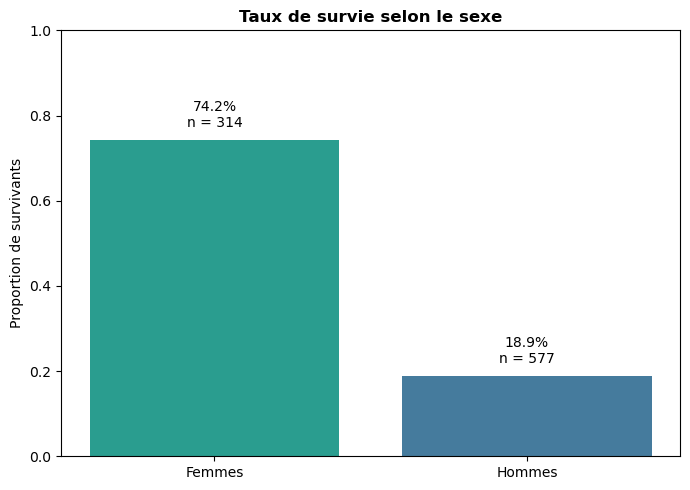

,Taux de survie,Nombre de passagers
Sex,,
female,0.742038,314
male,0.188908,577


In [ ]:
figure_paths = []

survival_by_sex = train_clean.groupby("Sex", observed=True)["Survived"].agg(["mean", "size"])
survival_by_sex = survival_by_sex.reindex(["female", "male"])
labels = ["Femmes", "Hommes"]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, survival_by_sex["mean"], color=["#2A9D8F", "#457B9D"])
ax.set_title("Taux de survie selon le sexe", fontweight="bold")
ax.set_ylabel("Proportion de survivants")
ax.set_ylim(0, 1)
for bar, (_, row) in zip(bars, survival_by_sex.iterrows()):
    ax.annotate(
        f"{row['mean']:.1%}\nn = {int(row['size'])}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7), textcoords="offset points", ha="center", va="bottom",
    )
fig.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sex_figure_path = FIGURES_DIR / "survival_by_sex.png"
fig.savefig(sex_figure_path, dpi=160, bbox_inches="tight")
plt.show()
figure_paths.append(sex_figure_path)
display(survival_by_sex.rename(columns={"mean": "Taux de survie", "size": "Nombre de passagers"}))

### 6.2 Taux de survie selon la classe du billet

La classe (`Pclass`) est présentée comme une catégorie ordonnée de 1 à 3. Les effectifs sont affichés avec les taux afin de donner du contexte aux comparaisons ; les résultats ne préjugent pas de la performance d'un modéle.

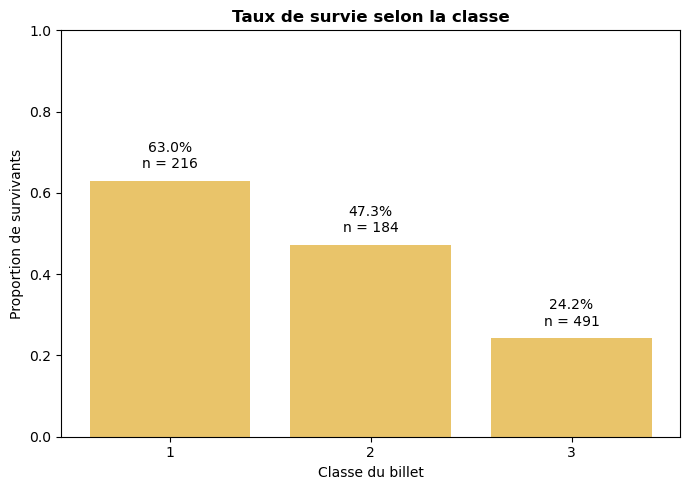

,Taux de survie,Nombre de passagers
Pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


In [8]:
survival_by_class = train_clean.groupby("Pclass", observed=True)["Survived"].agg(["mean", "size"]).reindex([1, 2, 3])

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(survival_by_class.index.astype(str), survival_by_class["mean"], color="#E9C46A")
ax.set_title("Taux de survie selon la classe", fontweight="bold")
ax.set_xlabel("Classe du billet")
ax.set_ylabel("Proportion de survivants")
ax.set_ylim(0, 1)
for bar, (_, row) in zip(bars, survival_by_class.iterrows()):
    ax.annotate(
        f"{row['mean']:.1%}\nn = {int(row['size'])}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7), textcoords="offset points", ha="center", va="bottom",
    )
fig.tight_layout()
class_figure_path = FIGURES_DIR / "survival_by_class.png"
fig.savefig(class_figure_path, dpi=160, bbox_inches="tight")
plt.show()
figure_paths.append(class_figure_path)
display(survival_by_class.rename(columns={"mean": "Taux de survie", "size": "Nombre de passagers"}))

### 6.3 Distribution des âges selon le statut de survie

Les histogrammes superposés comparent les distributions d'aâge des passagers survivants et non survivants. L'imputation de la médiane effectuée plus haut est incluse dans ces distributions ; les effectifs sont rappelés pour éviter de comparer uniquement les formes.

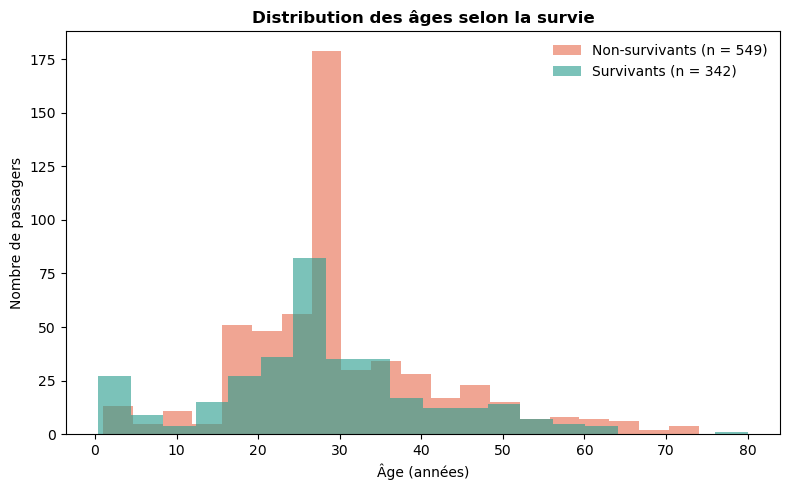

,count,median,mean
Survived,,,
Non-survivants,549,28.0,30.028233
Survivants,342,28.0,28.291433


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {0: "#E76F51", 1: "#2A9D8F"}
labels = {0: "Non-survivants", 1: "Survivants"}
for survived in (0, 1):
    ages = train_clean.loc[train_clean["Survived"].eq(survived), "Age"]
    ax.hist(ages, bins=20, alpha=0.62, color=colors[survived],
            label=f"{labels[survived]} (n = {len(ages)})")
ax.set_title("Distribution des âges selon la survie", fontweight="bold")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
ax.legend(frameon=False)
fig.tight_layout()
age_figure_path = FIGURES_DIR / "age_distribution_by_survival.png"
fig.savefig(age_figure_path, dpi=160, bbox_inches="tight")
plt.show()
figure_paths.append(age_figure_path)
display(train_clean.groupby("Survived", observed=True)["Age"].agg(["count", "median", "mean"]).rename(index={0: "Non-survivants", 1: "Survivants"}))

### 6.4 Distribution des tarifs selon la classe

Le diagramme en boîtes compare la médiane et l'eétendue interquartile des tarifs par classe. Les points extrémes sont masqués pour améliorer la lisibilité du graphique ; les statistiques récapitulatives affichent aussi les quartiles.

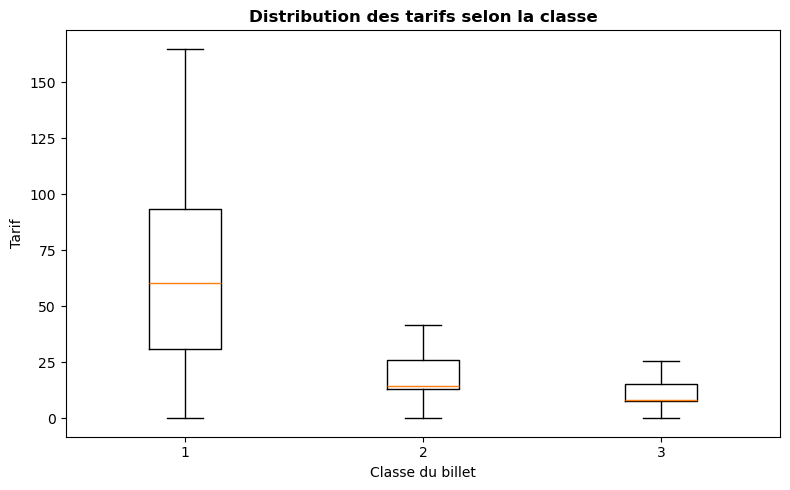

,Q1,Médiane,Q3
Pclass,,,
1,30.92395,60.2875,93.5
2,13.00000,14.2500,26.0
3,7.75000,8.0500,15.5


In [10]:
fare_by_class = [train_clean.loc[train_clean["Pclass"].eq(level), "Fare"] for level in (1, 2, 3)]
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(fare_by_class, tick_labels=["1", "2", "3"], showfliers=False)
ax.set_title("Distribution des tarifs selon la classe", fontweight="bold")
ax.set_xlabel("Classe du billet")
ax.set_ylabel("Tarif")
fig.tight_layout()
fare_figure_path = FIGURES_DIR / "fare_distribution_by_class.png"
fig.savefig(fare_figure_path, dpi=160, bbox_inches="tight")
plt.show()
figure_paths.append(fare_figure_path)
display(train_clean.groupby("Pclass", observed=True)["Fare"].quantile([0.25, 0.5, 0.75]).unstack().rename(columns={0.25: "Q1", 0.5: "Médiane", 0.75: "Q3"}))

## 7. Export des résultats

Les jeux nettoyés et le rapport de qualité sont enregistrés dans `data/processed/`. Les quatre graphiques sont sauvegardés individuellement dans `reports/figures/`.

In [11]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train_output = PROCESSED_DIR / "train_clean.csv"
test_output = PROCESSED_DIR / "test_clean.csv"
report_output = PROCESSED_DIR / "cleaning_summary.csv"

train_clean.to_csv(train_output, index=False, encoding="utf-8-sig")
test_clean.to_csv(test_output, index=False, encoding="utf-8-sig")
quality_report.to_csv(report_output, index=False, encoding="utf-8-sig")

print("Fichiers générés :")
for output_path in (train_output, test_output, report_output, *figure_paths):
    print(f"- {output_path.relative_to(PROJECT_ROOT)} ({output_path.stat().st_size:,} octets)")

Fichiers générés :
- data\processed\train_clean.csv (67,887 octets)
- data\processed\test_clean.csv (31,751 octets)
- data\processed\cleaning_summary.csv (472 octets)
- reports\figures\survival_by_sex.png (35,523 octets)
- reports\figures\survival_by_class.png (40,892 octets)
- reports\figures\age_distribution_by_survival.png (48,384 octets)
- reports\figures\fare_distribution_by_class.png (28,460 octets)


## 8. Vérification des fichiers produits

Les fichiers exportés sont relus afin de confirmer leur nombre de lignes, leurs colonnes et l'absence de valeurs manquantes dans les variables nettoyées.

In [12]:
train_export = pd.read_csv(train_output)
test_export = pd.read_csv(test_output)
report_export = pd.read_csv(report_output)

assert len(train_export) == len(df_train)
assert len(test_export) == len(df_test)
assert train_export["PassengerId"].is_unique
assert test_export["PassengerId"].is_unique
assert train_export[cleaned_columns].notna().all().all()
assert test_export[cleaned_columns].notna().all().all()
assert train_export["Survived"].isin([0, 1]).all()
assert test_export.columns.tolist() == [column for column in train_export.columns if column != "Survived"]
assert len(figure_paths) == 4 and all(path.is_file() and path.stat().st_size > 0 for path in figure_paths)

print("Export validé.")
print(f"Entraînement nettoyé : {train_export.shape[0]} lignes, {train_export.shape[1]} colonnes")
print(f"Test nettoyé : {test_export.shape[0]} lignes, {test_export.shape[1]} colonnes")
display(train_export.head())
display(test_export.head())

Export validé.
Entraînement nettoyé : 891 lignes, 12 colonnes
Test nettoyé : 418 lignes, 11 colonnes


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,Q,Unknown
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,S,Unknown
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,Q,Unknown
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,S,Unknown
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,S,Unknown
